# Chimera v2.4 — α and Δα biological analysis

This is the paper-quality deep dive into the two first-class outputs of
Chimera: the per-gene integration coefficient **α** and its shift from the
sequence-conservation prior **Δα = α − prior**.

The v2.4 thesis is that Δα carries *independent* information from protein
identity alone — it reports whether a gene is expression-conserved (high α,
Δα > 0) or expression-divergent (low α, Δα < 0) **after controlling for the
sequence-level prior**. This notebook produces the figure set an external
reader needs to believe that narrative:

1. α and Δα distributions (and their relationship to the prior)
2. α trajectory over training
3. correction magnitudes (Caveat 28 diagnostic)
4. top/bottom Δα genes with human gene symbols
5. α × S_g complementarity (FQR corroborates α)
6. α × residual L-shape at finer stratification
7. Saturation check with tight round2 thresholds

All panels re-render on any run that exposes the `final_state.npz` and
`alpha_snapshots/` artefacts — change `RUN_NAME` below to analyse a
different run.


In [1]:
import sys
from pathlib import Path

HERE = Path.cwd()
sys.path.insert(0, str(HERE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as spstats

import _paper_utils as pu
pu.set_paper_style()

RUN_NAME = "iter16-slow-classifier"
SAVE_FIGS = False

run = pu.load_run(RUN_NAME)
fs = run["final_state"]
snapshots = run.get("snapshots", [])
cfg = run["config"]

adata = pu.load_adata_for_run(run)
gene_names = pu.annotate_genes_with_names(adata.var_names)

alpha = fs["alpha"]
prior = fs["prior"]
dalpha = alpha - prior
corr = fs["correction"]
S_g = fs["S_g_ema"]
res_rms = fs["residual_rms"]

species_names = list(adata.obs["species"].astype("category").cat.categories)
n_species = len(species_names)
n_genes = len(alpha)

print(f"run: {RUN_NAME}")
print(f"genes: {n_genes}  species: {species_names}")
print(f"α: mean={alpha.mean():.3f} std={alpha.std():.3f}  range=[{alpha.min():.3f}, {alpha.max():.3f}]")
print(f"Δα: mean={dalpha.mean():+.3f} std={dalpha.std():.3f}  range=[{dalpha.min():+.3f}, {dalpha.max():+.3f}]")
print(f"|correction|: median={np.median(np.abs(corr)):.3f}  mean={np.abs(corr).mean():.3f}")

FIG_DIR = run["run_dir"] / "paper_figures_11"
if SAVE_FIGS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=220, bbox_inches="tight")
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")


run: iter16-slow-classifier
genes: 8430  species: ['Human', 'Monkey']
α: mean=0.788 std=0.150  range=[0.142, 0.995]
Δα: mean=-0.012 std=0.100  range=[-0.368, +0.392]
|correction|: median=0.452  mean=0.575


## §1 · Distributions of α, Δα, and the prior

**Figure 1.** Joint view of the three per-gene quantities at end-of-training.

Expectations (round2 OAI §1327 / §1338):
- α continuous with no pinning at 0 or 1,
- Δα two-sided with most mass near zero,
- Scatter α vs prior lies ≈ diagonally with a visible cloud above
  *and* below — not a band pinned below the diagonal (FM4 signature).


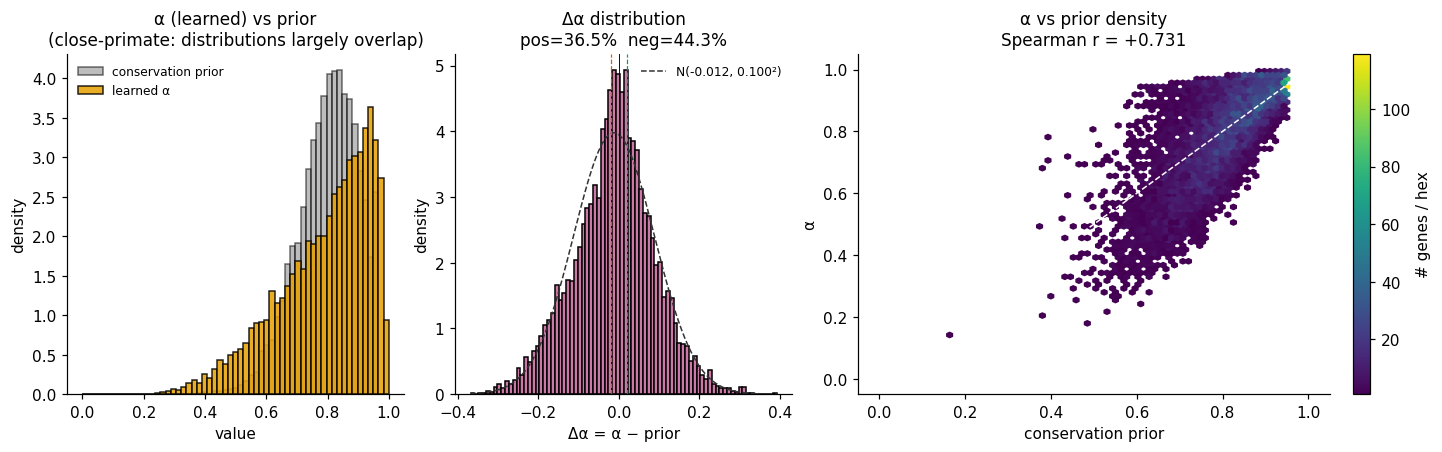

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0),
                         gridspec_kw=dict(width_ratios=[1, 1, 1.4]))

# (a) α histogram with prior overlay
ax = axes[0]
bins = np.linspace(0, 1, 60)
ax.hist(prior, bins=bins, color="#888888", alpha=0.55, label="conservation prior",
        edgecolor="k", lw=0.3, density=True)
ax.hist(alpha, bins=bins, color="#E69F00", alpha=0.85, label="learned α",
        edgecolor="k", lw=0.3, density=True)
ax.set_xlabel("value")
ax.set_ylabel("density")
ax.set_title("α (learned) vs prior\n(close-primate: distributions largely overlap)")
ax.legend(loc="upper left", fontsize=8)

# (b) Δα histogram with Gaussian fit
ax = axes[1]
x = np.linspace(dalpha.min(), dalpha.max(), 400)
mu_d, sd_d = dalpha.mean(), dalpha.std()
ax.hist(dalpha, bins=80, color="#CC79A7", edgecolor="k", lw=0.3, density=True)
ax.plot(x, spstats.norm.pdf(x, mu_d, sd_d), color="#333", lw=1, ls="--",
        label=f"N({mu_d:+.3f}, {sd_d:.3f}²)")
ax.axvline(0.02, color="#009E73", lw=0.8, ls="--")
ax.axvline(-0.02, color="#D55E00", lw=0.8, ls="--")
ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("Δα = α − prior")
ax.set_ylabel("density")
ax.set_title(f"Δα distribution\npos={(dalpha>0.02).mean():.1%}  neg={(dalpha<-0.02).mean():.1%}")
ax.legend(fontsize=8)

# (c) α vs prior scatter with a density-coloured hexbin
ax = axes[2]
hb = ax.hexbin(prior, alpha, gridsize=60, cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=ax, label="# genes / hex")
ax.plot([0, 1], [0, 1], ls="--", color="white", lw=1.0)
sp_r = spstats.spearmanr(prior, alpha).correlation
ax.set_xlabel("conservation prior")
ax.set_ylabel("α")
ax.set_title(f"α vs prior density\nSpearman r = {sp_r:+.3f}")

# constrained_layout is on via rcParams; do not tight_layout after a colorbar
savefig(fig, "fig11_1_distributions")
plt.show()


## §2 · α trajectory over training

**Figure 2.** α evolution. Panel (a) plots a random subsample of per-gene
α(t) in grey with the mean of α(t) overlaid in bold; panel (b) shows the
per-epoch L1 drift between consecutive snapshots (E7.1 stability check);
panel (c) shows α and Δα distributions *stratified by sampled epochs* to
visualise how the GIN gradually carves out the two-sided Δα mass.

*Round2 cites:* BEG §21, OAI §905 (composite convergence), CRE §440 for
the GIN-learning dynamics intuition.


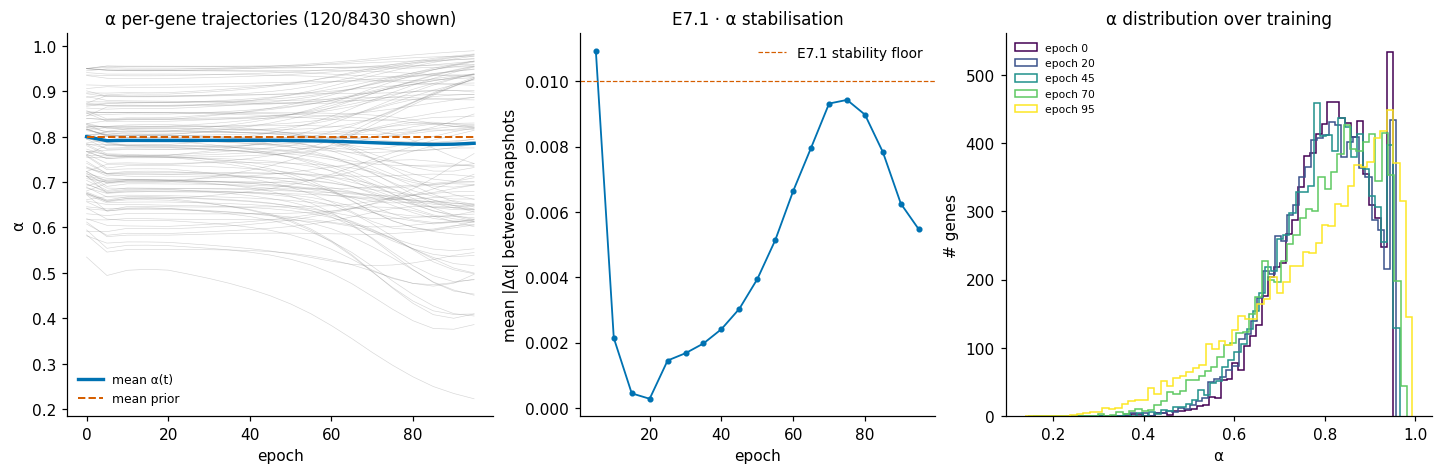

In [3]:
traj = pu.collect_alpha_trajectory(snapshots)
epochs = traj["epochs"]
a_hist = traj["alpha"]  # (E, G)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2),
                         gridspec_kw=dict(width_ratios=[1.2, 1, 1.2]))

# (a) per-gene trajectories (subsample) + mean
ax = axes[0]
rng = np.random.default_rng(0)
pick = rng.choice(n_genes, size=min(120, n_genes), replace=False)
for gi in pick:
    ax.plot(epochs, a_hist[:, gi], color="#888888", lw=0.4, alpha=0.35)
ax.plot(epochs, a_hist.mean(axis=1), color="#0072B2", lw=2.2, label="mean α(t)")
ax.plot(epochs, np.full_like(epochs, prior.mean(), dtype=float),
        color="#D55E00", lw=1.3, ls="--", label="mean prior")
ax.set_xlabel("epoch")
ax.set_ylabel("α")
ax.set_title(f"α per-gene trajectories ({len(pick)}/{n_genes} shown)")
ax.legend(fontsize=8)

# (b) consecutive-snapshot L1 drift
ax = axes[1]
if len(epochs) > 1:
    l1 = np.mean(np.abs(np.diff(a_hist, axis=0)), axis=1)
    ax.plot(epochs[1:], l1, color="#0072B2", lw=1.2, marker="o", ms=3)
    ax.axhline(0.01, ls="--", color="#D55E00", lw=0.8, label="E7.1 stability floor")
    ax.set_xlabel("epoch")
    ax.set_ylabel("mean |Δα| between snapshots")
    ax.set_title("E7.1 · α stabilisation")
    ax.legend()

# (c) α distribution at a handful of epochs
ax = axes[2]
if len(epochs) >= 3:
    snap_idx = np.linspace(0, len(epochs) - 1, 5).astype(int)
    cmap = plt.cm.viridis
    for i, idx in enumerate(snap_idx):
        ax.hist(a_hist[idx], bins=60, histtype="step", lw=1.4,
                color=cmap(i / max(1, len(snap_idx) - 1)),
                label=f"epoch {int(epochs[idx])}")
ax.set_xlabel("α")
ax.set_ylabel("# genes")
ax.set_title("α distribution over training")
ax.legend(fontsize=7)

# constrained_layout is on globally
savefig(fig, "fig11_2_trajectory")
plt.show()


## §3 · Correction magnitudes

**Figure 3.** |correction| histogram at end-of-training — the direct
diagnostic from *critical_reexamination* Caveat 28 for GIN under-training.
The spec warns if ≥95 % of genes have `|correction| < 0.1` (GIN stuck
near zero, so α ≈ prior with no learning). The healthy regime looks
like a right-skewed distribution with most mass above 0.1.

Panel (b) shows Δα vs correction — these should correlate strongly by
construction (`Δα = σ(logit(prior) + correction) − prior`); the fit
gives a sanity check.


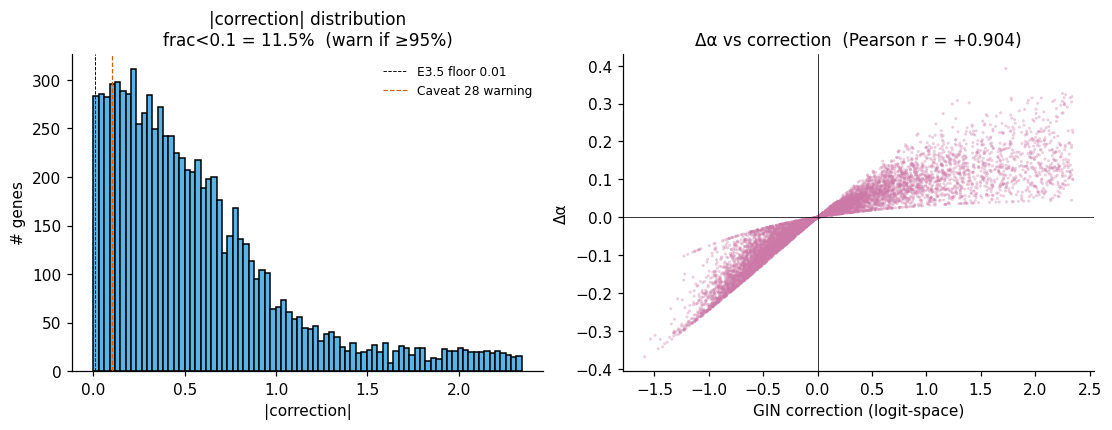

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

# (a) |correction| histogram
ax = axes[0]
ax.hist(np.abs(corr), bins=80, color="#56B4E9", edgecolor="k", lw=0.3)
ax.axvline(0.01, ls="--", color="k", lw=0.6, label="E3.5 floor 0.01")
ax.axvline(0.10, ls="--", color="#D55E00", lw=0.8, label="Caveat 28 warning")
frac_small = float((np.abs(corr) < 0.1).mean())
ax.set_xlabel("|correction|")
ax.set_ylabel("# genes")
ax.set_title(f"|correction| distribution\nfrac<0.1 = {frac_small:.1%}  "
             f"(warn if ≥95%)")
ax.legend(fontsize=8)

# (b) Δα vs correction (must be monotone by construction)
ax = axes[1]
ax.scatter(corr, dalpha, s=4, alpha=0.35, color="#CC79A7", edgecolors="none")
ax.axvline(0, color="k", lw=0.5)
ax.axhline(0, color="k", lw=0.5)
cor_r = spstats.pearsonr(corr, dalpha).statistic
ax.set_xlabel("GIN correction (logit-space)")
ax.set_ylabel("Δα")
ax.set_title(f"Δα vs correction  (Pearson r = {cor_r:+.3f})")

# constrained_layout is on globally
savefig(fig, "fig11_3_correction")
plt.show()


## §4 · Top and bottom Δα genes (biology narrative)

**Figure 4 / Table.** The genes with the largest positive Δα (model sees
them as *more* conserved than the prior alone suggests) and the largest
negative Δα (*less* conserved) tell a biology story at end-of-training.
For this subset we annotate each gene with its human gene symbol via the
ortholog table — useful for the narrative around housekeeping vs.
species-specific expression.

The point of this panel is that the top-Δα list should be biologically
sensible — typically housekeeping / ribosomal / mitochondrial genes — and
the bottom-Δα list should be enriched for species-specific / immune /
regulatory genes. A run that places random gene families in these tails
is a sign of GIN over-fitting the training noise.


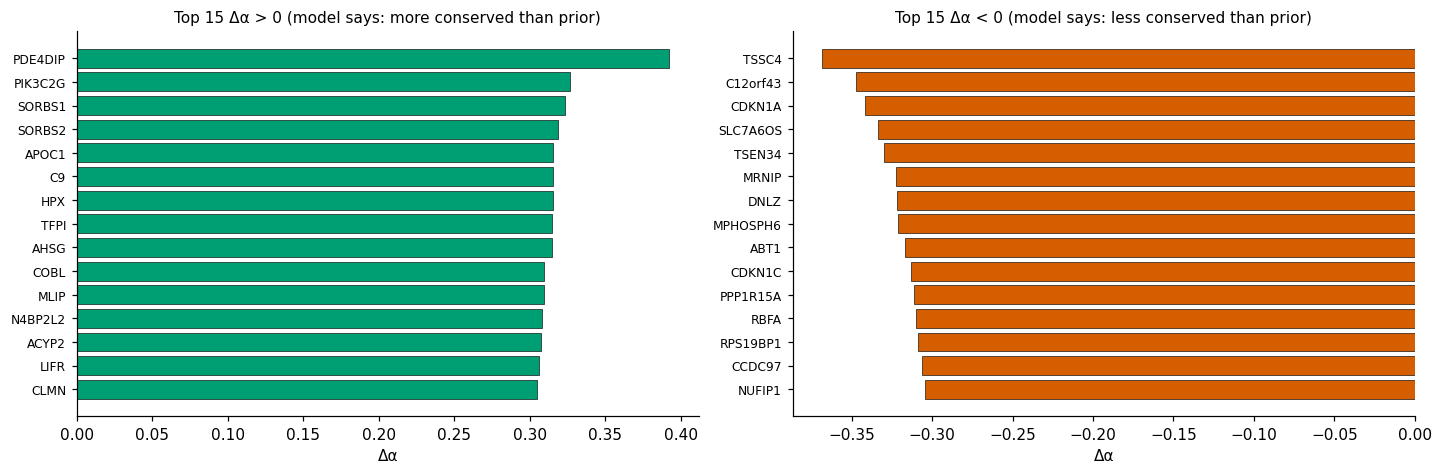

Top Δα positive (head):
 symbol  prior  alpha  delta_alpha  S_g_ema  residual_rms
PDE4DIP  0.392  0.784        0.392    0.061         0.095
PIK3C2G  0.610  0.937        0.327    0.256         0.026
 SORBS1  0.617  0.940        0.323    0.077         0.028
 SORBS2  0.627  0.946        0.319    0.376         0.057
  APOC1  0.627  0.942        0.315    0.032         0.046
     C9  0.630  0.946        0.315    0.327         0.067
    HPX  0.600  0.915        0.315    0.078         0.035
   TFPI  0.610  0.924        0.315    0.109         0.062
   AHSG  0.574  0.889        0.315    0.043         0.020
   COBL  0.628  0.937        0.309    0.148         0.012
   MLIP  0.583  0.892        0.309    0.171         0.057
N4BP2L2  0.606  0.914        0.308    0.018         0.029
  ACYP2  0.391  0.699        0.308    0.003         0.049
   LIFR  0.637  0.943        0.306    1.001         0.052
   CLMN  0.632  0.937        0.305    0.153         0.029

Top Δα negative (head):
  symbol  prior  alpha 

In [5]:
df = pd.DataFrame({
    "gene": adata.var_names,
    "symbol": gene_names.values,
    "prior": prior,
    "alpha": alpha,
    "delta_alpha": dalpha,
    "abs_correction": np.abs(corr),
    "S_g_ema": S_g,
    "residual_rms": res_rms,
})

TOP_K = 15
top_pos = df.sort_values("delta_alpha", ascending=False).head(TOP_K).reset_index(drop=True)
top_neg = df.sort_values("delta_alpha", ascending=True).head(TOP_K).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

for ax, tbl, title, c in [
    (axes[0], top_pos, "Top 15 Δα > 0 (model says: more conserved than prior)", "#009E73"),
    (axes[1], top_neg, "Top 15 Δα < 0 (model says: less conserved than prior)", "#D55E00"),
]:
    y = np.arange(len(tbl))
    ax.barh(y, tbl["delta_alpha"].values, color=c, edgecolor="k", lw=0.4)
    ax.set_yticks(y)
    ax.set_yticklabels(tbl["symbol"].values, fontsize=8)
    ax.invert_yaxis()
    ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel("Δα")
    ax.set_title(title, fontsize=10)

# constrained_layout is on globally
savefig(fig, "fig11_4_topgenes")
plt.show()

print("Top Δα positive (head):")
print(top_pos[["symbol", "prior", "alpha", "delta_alpha", "S_g_ema", "residual_rms"]]
      .to_string(index=False, float_format='%.3f'))
print("\nTop Δα negative (head):")
print(top_neg[["symbol", "prior", "alpha", "delta_alpha", "S_g_ema", "residual_rms"]]
      .to_string(index=False, float_format='%.3f'))


## §5 · α × S_g (FQR) complementarity

**Figure 5.** The FQR term's EMA `S_g_ema` should be *low* for high-α genes
(the residual carries little signal, so the fit-reward is minimal) and
*higher* for low-α genes (residual is meaningful, so the fit-reward
matters). Per round2 BEG §18 / §322, S_g > 0 typically acts on 20–50 %
of genes — the ones the GIN has flagged as partially species-specific.

If this panel shows a flat S_g vs α, either `λ_fit` is too low (FQR
inactive) or `λ_fit` over-drives S_g so all genes saturate.


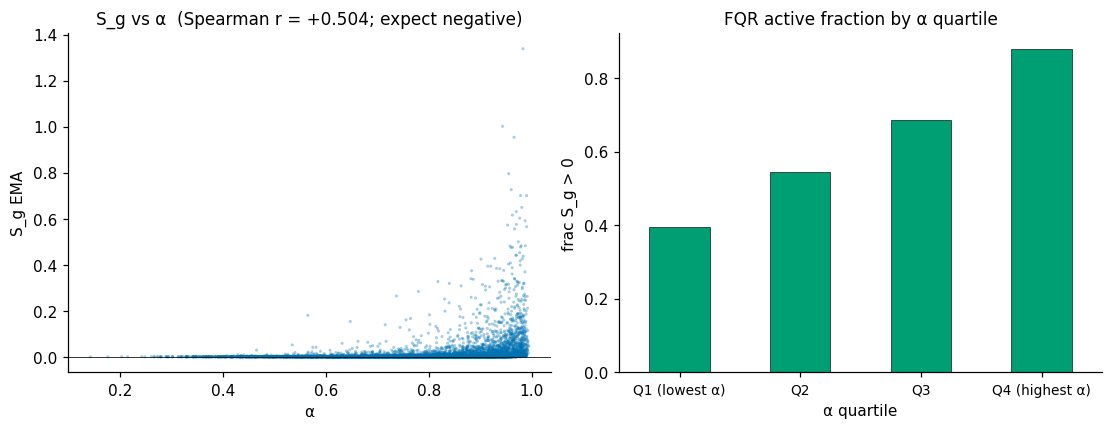

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

ax = axes[0]
ax.scatter(alpha, S_g, s=4, alpha=0.35, color="#0072B2", edgecolors="none")
ax.axhline(0, color="k", lw=0.5)
sg_r = spstats.spearmanr(alpha, S_g).correlation
ax.set_xlabel("α")
ax.set_ylabel("S_g EMA")
ax.set_title(f"S_g vs α  (Spearman r = {sg_r:+.3f}; expect negative)")

ax = axes[1]
# Fraction with S_g > 0 in α quartiles
qs = np.quantile(alpha, [0, 0.25, 0.5, 0.75, 1.0])
bucket = pd.cut(alpha, bins=qs, labels=["Q1 (lowest α)", "Q2", "Q3", "Q4 (highest α)"],
                include_lowest=True)
frac = pd.Series(S_g > 0).groupby(bucket, observed=False).mean()
frac.plot(kind="bar", ax=ax, color="#009E73", edgecolor="k", lw=0.4)
ax.set_ylabel("frac S_g > 0")
ax.set_xlabel("α quartile")
ax.set_title("FQR active fraction by α quartile")
plt.setp(ax.get_xticklabels(), rotation=0, fontsize=9)

# constrained_layout is on globally
savefig(fig, "fig11_5_sg")
plt.show()


## §6 · α × residual L-shape, stratified by prior

**Figure 6.** Revisits the L-shape (E4.2) with stratification. The L-shape
must hold *at every prior band*, not just globally. If high-α genes at
low prior show large residuals, the GIN is using α as a species-ID leak
for those genes — suggestive of FM-D (shared path picks up species info).

The left panel reproduces the global L-shape; the right panel stratifies
genes into three equal-width prior bands and overlays the L-shape within
each. A clean run keeps the downward trend visible inside each band.


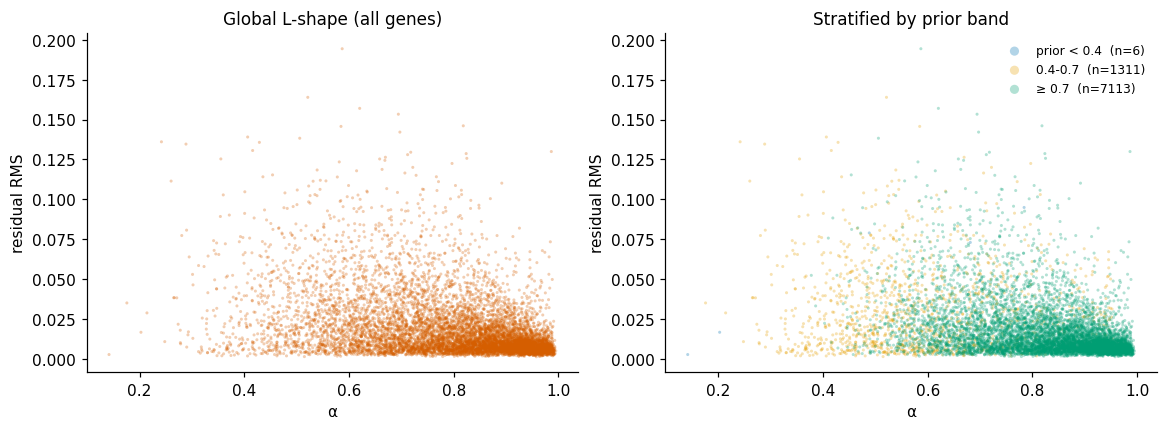

  prior band '0.4-0.7' (n= 1311):  Spearman r(α, res) = +0.020
  prior band '≥ 0.7' (n= 7113):  Spearman r(α, res) = -0.372


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))

# global L-shape
ax = axes[0]
ax.scatter(alpha, res_rms, s=4, alpha=0.3, color="#D55E00", edgecolors="none")
ax.set_xlabel("α")
ax.set_ylabel("residual RMS")
ax.set_title("Global L-shape (all genes)")

# stratified by prior
ax = axes[1]
bands = pd.cut(prior, bins=[0, 0.4, 0.7, 1.0],
               labels=["prior < 0.4", "0.4-0.7", "≥ 0.7"])
palette = ["#0072B2", "#E69F00", "#009E73"]
for band, col in zip(bands.categories, palette):
    mask = bands == band
    if mask.sum() < 5:
        continue
    ax.scatter(alpha[mask], res_rms[mask], s=4, alpha=0.3,
               color=col, label=f"{band}  (n={int(mask.sum())})", edgecolors="none")
ax.set_xlabel("α")
ax.set_ylabel("residual RMS")
ax.set_title("Stratified by prior band")
ax.legend(fontsize=8, markerscale=3)

# constrained_layout is on globally
savefig(fig, "fig11_6_Lshape")
plt.show()

# Inside each prior band: Spearman r(α, residual)
for band in bands.categories:
    m = np.asarray(bands == band)
    if m.sum() < 20:
        continue
    r = spstats.spearmanr(alpha[m], res_rms[m]).correlation
    print(f"  prior band '{band}' (n={m.sum():>5d}):  Spearman r(α, res) = {r:+.3f}")


## §7 · α saturation — the tight thresholds

**Figure 7.** Round2 Caveat 29 asks for α to avoid the sigmoid extremes
— ideally `frac(α < 0.02) < 5%` and `frac(α > 0.98) < 5%`. This panel
overlays the tight thresholds on the α histogram and shows what fraction
of genes is at each extreme.

On close-species pairs a modest over-population of the upper extreme
(α ≥ 0.98) is biologically reasonable — many housekeeping families
really are near-perfectly conserved. A large lower-extreme population is
the red flag (it would mean the model says these genes are *entirely*
species-specific — usually a sign FM1 is operating on some gene subset).


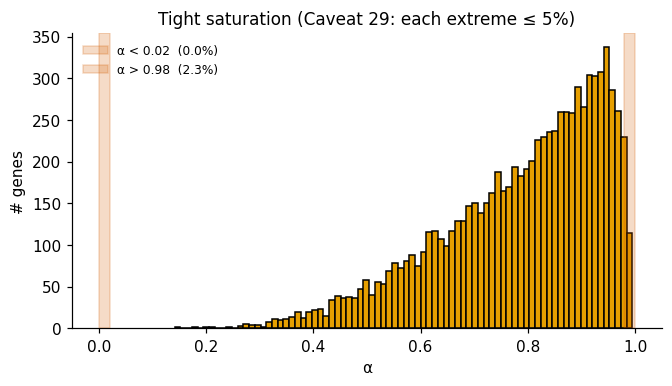

frac(α < 0.02) = 0.0%  (round2 ceiling 5% — overshoot: no)
frac(α > 0.98) = 2.3%  (round2 ceiling 5% — overshoot: no)


In [8]:
sat = pu.saturation_stats(alpha, low=0.02, high=0.98)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(alpha, bins=80, color="#E69F00", edgecolor="k", lw=0.3)
ax.axvspan(0, 0.02, color="#D55E00", alpha=0.22, label=f"α < 0.02  ({sat['frac_below_low']:.1%})")
ax.axvspan(0.98, 1.0, color="#D55E00", alpha=0.22, label=f"α > 0.98  ({sat['frac_above_high']:.1%})")
ax.set_xlabel("α")
ax.set_ylabel("# genes")
ax.set_title("Tight saturation (Caveat 29: each extreme ≤ 5%)")
ax.legend(loc="upper left", fontsize=8)

# constrained_layout is on globally
savefig(fig, "fig11_7_saturation")
plt.show()

overshoot_low = "yes" if sat["frac_below_low"] > 0.05 else "no"
overshoot_high = "yes" if sat["frac_above_high"] > 0.05 else "no"
print(f"frac(α < 0.02) = {sat['frac_below_low']:.1%}  (round2 ceiling 5% — overshoot: {overshoot_low})")
print(f"frac(α > 0.98) = {sat['frac_above_high']:.1%}  (round2 ceiling 5% — overshoot: {overshoot_high})")


## §8 · Do α values change when you look inside a cell type?

Chimera v2.4 α is *per-gene*, not per-(gene × cell-type); this is the
documented v2.4 simplification (critical_reexamination "Problem 4"; also
Caveat 31 for multi-domain proteins). This panel corroborates that the
gene ordering by α doesn't silently reflect tissue-composition — we compute
per-cell-type expression means from the raw counts and check whether α
tracks cell-type-specific expression strength.

Interpretation: if α correlates strongly with *any one* cell type's
average expression much more than the others, it would suggest α is
tracking tissue composition differences, not true cross-species
conservation. A healthy run shows α weakly correlated with per-cell-type
means (all correlations < 0.4 or so) and similar across cell types.


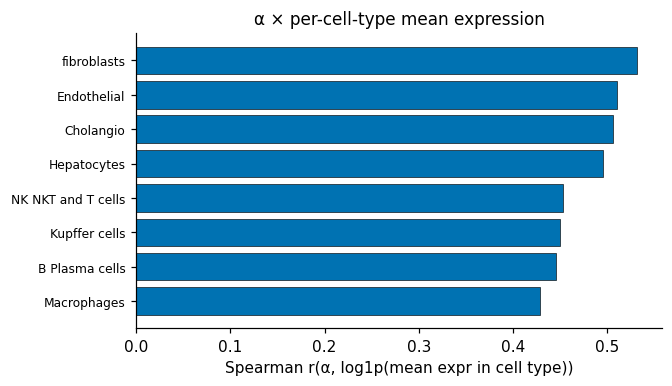

         cell_type  spearman_r
    B Plasma cells    0.445857
         Cholangio    0.506349
       Endothelial    0.510819
       Hepatocytes    0.495977
     Kupffer cells    0.449403
       Macrophages    0.428972
NK NKT and T cells    0.453525
       fibroblasts    0.531342


In [9]:
# Per-cell-type mean expression; check α is not just tracking one cell type.
import scipy.sparse as sp
X = adata.X
if sp.issparse(X):
    X = X.toarray()

if "cell_type" in adata.obs:
    ctypes = adata.obs["cell_type"].astype(str).values
    unique_ct = sorted(np.unique(ctypes))
    per_ct_means = []
    for ct in unique_ct:
        m = ctypes == ct
        if m.sum() < 5:
            continue
        per_ct_means.append((ct, X[m].mean(axis=0)))

    fig, ax = plt.subplots(figsize=(6, 3.4))
    corrs = []
    for ct, mu_ct in per_ct_means:
        r = spstats.spearmanr(alpha, np.log1p(mu_ct)).correlation
        corrs.append((ct, r))
    names, rs = zip(*corrs)
    order = np.argsort(rs)
    names = [names[i] for i in order]
    rs = [rs[i] for i in order]
    ax.barh(np.arange(len(names)), rs, color="#0072B2", edgecolor="k", lw=0.4)
    ax.set_yticks(np.arange(len(names)))
    ax.set_yticklabels(names, fontsize=8)
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("Spearman r(α, log1p(mean expr in cell type))")
    ax.set_title("α × per-cell-type mean expression")

    # constrained_layout is on globally
    savefig(fig, "fig11_8_alpha_vs_celltype")
    plt.show()
    print(pd.DataFrame(corrs, columns=["cell_type", "spearman_r"]).to_string(index=False))
else:
    print("adata has no 'cell_type' — skipping §8")


## §9 · Closing

The figures above give the α / Δα deep dive needed to interpret a
Chimera model beyond the 32 pass/fail gates in notebook 10. Each panel is
*also* a diagnostic: if the run trained poorly, at least one of §1–§8
will look wrong (e.g., §2 flat mean-α trajectory → GIN dead; §4 empty
tails → Δα one-sided; §6 L-shape broken inside a prior band →
z-leakage; §7 heavy saturation at the low extreme → FM1).

Together with notebook 10 (the gate-level validation) and
`training/workflow.md` (the full diagnostic ladder), this is the
round2-authorised toolkit for judging a Chimera run.

**Reproducibility note.** Everything above is deterministic given
`RUN_NAME`. The scipy KDE and correlations use no RNG; the only
stochastic element is the random gene subsample in §2, seeded by
`np.random.default_rng(0)`.
